In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import skfuzzy as fuzz
import sys
import os

sys.path.append(os.path.abspath(".."))

from src.data.load_master_data import load_master_data

df = load_master_data()

print(f"Shape: {df.shape}")
display(df.head())

Shape: (25939, 46)


,season,round,driver_id,driver_name,constructor_id,grid,position,points,laps,status,...,podium,win,pole_position,front_row,weighted_points_at_circuit,driver_circuit_delta,points_last_5_races,current_season_points,avg_points_per_season,constructor_points_current_season
0,1950,1,farina,Nino Farina,alfa,1,1,9.0,70,Finished,...,1,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0
1,1950,1,fagioli,Luigi Fagioli,alfa,2,2,6.0,70,Finished,...,1,0,0,1,0.0,0.0,0.0,0.0,0.0,0.0
2,1950,1,reg_parnell,Reg Parnell,alfa,4,3,4.0,70,Finished,...,1,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,1950,1,cabantous,Yves Cabantous,lago,6,4,3.0,68,+2 Laps,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
4,1950,1,rosier,Louis Rosier,lago,9,5,2.0,68,+2 Laps,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [2]:
# Choose numerical features that describe driver performance

cluster_features = [
    "grid",
    "points",
    "driver_age",
    "current_season_points",
    "avg_points_per_season",
    "points_last_5_races",
    "weighted_points_at_circuit",
    "driver_circuit_delta",
    "q1_seconds",
    "q2_seconds",
    "q3_seconds"
]

# Create subset
cluster_df = df[cluster_features].copy()

print("Shape:", cluster_df.shape)
print("\nMissing values:")
print(cluster_df.isnull().sum())

Shape: (25939, 11)

Missing values:
grid                          0
points                        0
driver_age                    0
current_season_points         0
avg_points_per_season         0
points_last_5_races           0
weighted_points_at_circuit    0
driver_circuit_delta          0
q1_seconds                    0
q2_seconds                    0
q3_seconds                    0
dtype: int64


In [3]:
# Fill NaN values with the median of each column
for col in cluster_features:
    cluster_df[col] = cluster_df[col].fillna(
        cluster_df[col].median()
    )

print("NaN values after filling:")
print(cluster_df.isnull().sum())

NaN values after filling:
grid                          0
points                        0
driver_age                    0
current_season_points         0
avg_points_per_season         0
points_last_5_races           0
weighted_points_at_circuit    0
driver_circuit_delta          0
q1_seconds                    0
q2_seconds                    0
q3_seconds                    0
dtype: int64


In [4]:
# Scale the data
# Fuzzy C-Means is sensitive to feature scaling,
# so columns with larger values would otherwise dominate

scaler = StandardScaler()

X_scaled = scaler.fit_transform(cluster_df)

print("Scaled data shape:", X_scaled.shape)
print("Mean per column (should be ~0):", X_scaled.mean(axis=0).round(2))
print("Standard deviation per column (should be ~1):", X_scaled.std(axis=0).round(2))

Scaled data shape: (25939, 11)
Mean per column (should be ~0): [ 0.  0.  0. -0. -0.  0. -0.  0. -0. -0. -0.]
Standard deviation per column (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


k=2: Silhouette Score = 0.5132
k=3: Silhouette Score = 0.3630
k=4: Silhouette Score = 0.2720
k=5: Silhouette Score = 0.2221
k=6: Silhouette Score = 0.2305
k=7: Silhouette Score = 0.2319


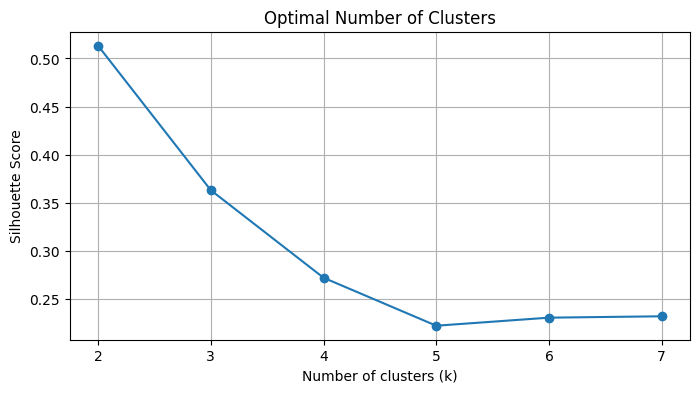


Best number of clusters: 2


In [5]:
# Find the optimal number of clusters using the Silhouette Score
# A score close to 1 is good, while a negative score indicates poor clustering

from sklearn.cluster import KMeans

silhouette_scores = []
k_values = range(2, 8)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"k={k}: Silhouette Score = {score:.4f}")

# Plot
plt.figure(figsize=(8, 4))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Optimal Number of Clusters")
plt.grid(True)
plt.show()

best_k = k_values[np.argmax(silhouette_scores)]
print(f"\nBest number of clusters: {best_k}")

In [6]:
# Fuzzy C-Means (FCM)

n_clusters = best_k
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    X_scaled.T,      # Transposed data matrix
    c=n_clusters,
    m=2,             # Fuzziness parameter
    error=0.005,     # Convergence threshold
    maxiter=1000,    # Maximum number of iterations
    init=None
)

print(f"FPC (Fuzzy Partition Coefficient): {fpc:.4f}")
print("FPC close to 1.0 = well-defined clusters, close to 0 = highly overlapping clusters")
print(f"\nMembership matrix shape: {u.shape}")
print("(number of clusters x number of rows)")

FPC (Fuzzy Partition Coefficient): 0.6818
FPC close to 1.0 = well-defined clusters, close to 0 = highly overlapping clusters

Membership matrix shape: (2, 25939)
(number of clusters x number of rows)


In [7]:
membership_df = pd.DataFrame(
    u.T,
    columns=[f"cluster_{i}_membership" for i in range(n_clusters)]
)

# Which cluster has the highest membership score?
membership_df["dominant_cluster"] = np.argmax(u, axis=0)

print("Distribution of dominant clusters:")
print(membership_df["dominant_cluster"].value_counts())

print("\nExample membership scores:")
print(membership_df.head(10))

Distribution of dominant clusters:
dominant_cluster
1    20309
0     5630
Name: count, dtype: int64

Example membership scores:
   cluster_0_membership  cluster_1_membership  dominant_cluster
0              0.369415              0.630585                 1
1              0.395020              0.604980                 1
2              0.238181              0.761819                 1
3              0.303969              0.696031                 1
4              0.267513              0.732487                 1
5              0.096489              0.903511                 1
6              0.233118              0.766882                 1
7              0.350097              0.649903                 1
8              0.047629              0.952371                 1
9              0.100034              0.899966                 1


In [8]:
df_clustered = df.copy()

for i in range(n_clusters):
    df_clustered[f"cluster_{i}_membership"] = u[i]

df_clustered["dominant_cluster"] = np.argmax(u, axis=0)

print(
    df_clustered[
        ["driver_id", "season", "dominant_cluster"] +
        [f"cluster_{i}_membership" for i in range(n_clusters)]
    ].head(10)
)

     driver_id  season  dominant_cluster  cluster_0_membership  \
0       farina    1950                 1              0.369415   
1      fagioli    1950                 1              0.395020   
2  reg_parnell    1950                 1              0.238181   
3    cabantous    1950                 1              0.303969   
4       rosier    1950                 1              0.267513   
5       gerard    1950                 1              0.096489   
6     harrison    1950                 1              0.233118   
7    etancelin    1950                 1              0.350097   
8    hampshire    1950                 1              0.047629   
9          fry    1950                 1              0.100034   

   cluster_1_membership  
0              0.630585  
1              0.604980  
2              0.761819  
3              0.696031  
4              0.732487  
5              0.903511  
6              0.766882  
7              0.649903  
8              0.952371  
9            

In [9]:
for cluster in range(n_clusters):
    print(f"\n{'='*50}")
    print(f"CLUSTER {cluster}")
    print(f"{'='*50}")

    cluster_data = df_clustered[
        df_clustered["dominant_cluster"] == cluster
    ]

    print(f"Number of rows: {len(cluster_data)}")
    print(f"\nAverage grid position: {cluster_data['grid'].mean():.1f}")
    print(f"Average points per race: {cluster_data['points'].mean():.2f}")
    print(f"Podium rate: {cluster_data['podium'].mean():.2%}")
    print(f"Victory rate: {cluster_data['win'].mean():.2%}")

    print(f"\nTop 10 drivers in cluster:")
    top_drivers = (
        cluster_data.groupby("driver_id")["points"]
        .mean()
        .sort_values(ascending=False)
        .head(10)
    )
    print(top_drivers)


CLUSTER 0
Number of rows: 5630

Average grid position: 6.9
Average points per race: 6.86
Podium rate: 27.74%
Victory rate: 10.89%

Top 10 drivers in cluster:
driver_id
max_verstappen    14.626106
hamilton          13.132895
piastri           10.955224
vettel            10.893993
alesi             10.000000
berger            10.000000
russell            9.813725
leclerc            9.812121
norris             9.202703
rosberg            9.130058
Name: points, dtype: float64

CLUSTER 1
Number of rows: 20309

Average grid position: 13.0
Average points per race: 0.85
Podium rate: 9.43%
Victory rate: 2.67%

Top 10 drivers in cluster:
driver_id
george_amick    6.000000
fangio          4.558148
wallard         4.500000
antonelli       4.000000
fagioli         4.000000
vukovich        3.800000
clark           3.449275
farina          3.441351
stewart         3.406250
prost           3.397059
Name: points, dtype: float64


Explained varians: [0.46027756 0.13333426]
Total explained varians: 59.36%


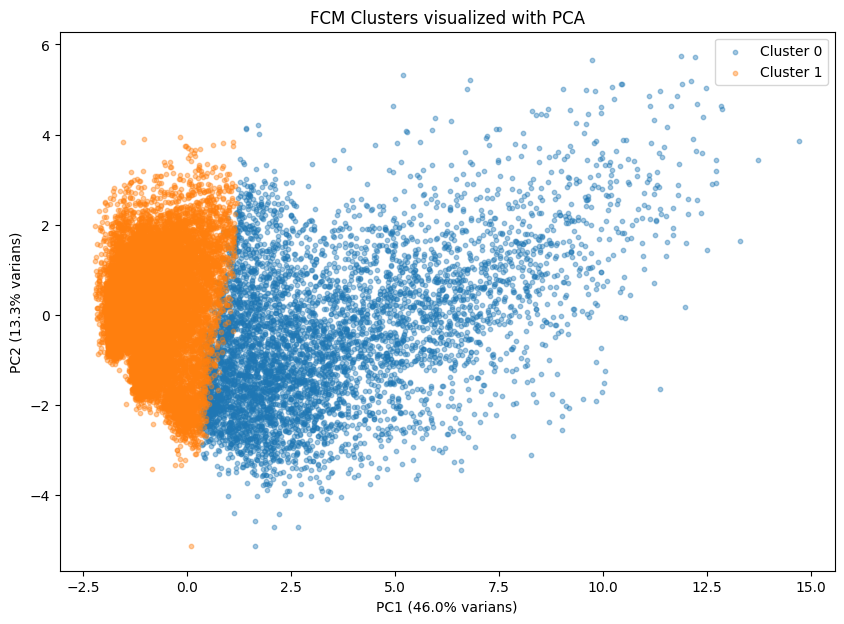

In [10]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"Explained varians: {pca.explained_variance_ratio_}")
print(f"Total explained varians: {pca.explained_variance_ratio_.sum():.2%}")

plt.figure(figsize=(10, 7))

for cluster in range(n_clusters):
    mask = df_clustered["dominant_cluster"] == cluster
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.4,
        s=10
    )

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} varians)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} varians)")
plt.title("FCM Clusters visualized with PCA")
plt.legend()
plt.show()

                  avg_grid  avg_points  podium_rate  win_rate  \
dominant_cluster                                                
0                    6.893       6.855        0.277     0.109   
1                   13.046       0.853        0.094     0.027   

                  avg_season_points  count  
dominant_cluster                            
0                            62.310   5630  
1                             5.973  20309  


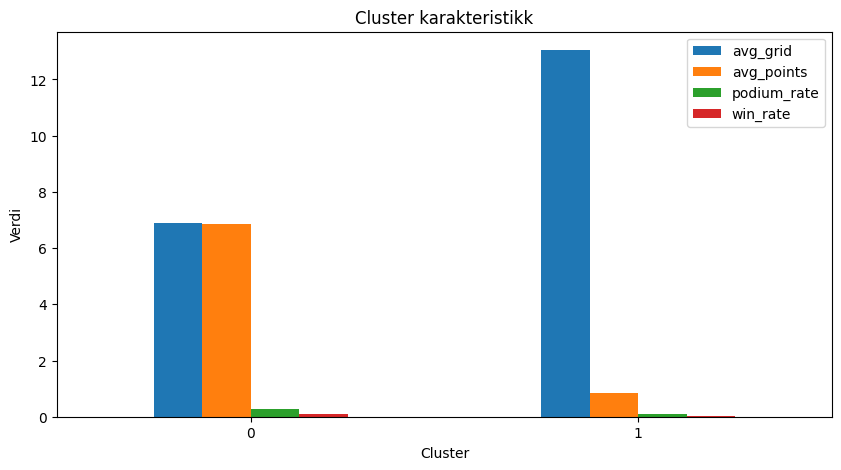

In [11]:
cluster_summary = df_clustered.groupby("dominant_cluster").agg(
    avg_grid          = ("grid", "mean"),
    avg_points        = ("points", "mean"),
    podium_rate       = ("podium", "mean"),
    win_rate          = ("win", "mean"),
    avg_season_points = ("current_season_points", "mean"),
    count             = ("driver_id", "count")
).round(3)

print(cluster_summary)

cluster_summary[["avg_grid", "avg_points", "podium_rate", "win_rate"]].plot(
    kind="bar",
    figsize=(10, 5),
    title="Cluster karakteristikk"
)
plt.xlabel("Cluster")
plt.ylabel("Verdi")
plt.xticks(rotation=0)
plt.legend(loc="upper right")
plt.show()

In [12]:
membership_cols = [f"cluster_{i}_membership" for i in range(n_clusters)]

df_clustered["max_membership"] = df_clustered[membership_cols].max(axis=1)
df_clustered["min_membership"] = df_clustered[membership_cols].min(axis=1)

fuzzy_drivers = df_clustered[
    df_clustered["max_membership"] < 0.6
][["driver_id", "season", "round", "dominant_cluster"] + membership_cols].head(20)

print("Drivers with uncertain cluster-dependency (fuzzy):")
print(fuzzy_drivers)

Drivers with uncertain cluster-dependency (fuzzy):
    driver_id  season  round  dominant_cluster  cluster_0_membership  \
33     farina    1950      2                 1              0.426003   
34    fagioli    1950      2                 1              0.406543   
79     farina    1950      4                 1              0.411572   
80    fagioli    1950      4                 1              0.408174   
98    fagioli    1950      5                 1              0.422088   
100    farina    1950      5                 1              0.418751   
111    fangio    1950      6                 1              0.415199   
112   fagioli    1950      6                 1              0.433198   
131    farina    1950      7                 1              0.424507   
134   fagioli    1950      7                 1              0.431234   
160    fangio    1951      1                 1              0.421654   
162    farina    1951      1                 1              0.440458   
215    farina

In [19]:
print("Cluster 0 - Example drivers:")
print(
    df_clustered[df_clustered["dominant_cluster"] == 0]
    ["driver_id"].value_counts().head(10)
)

print("\nCluster 1 - Example drivers:")
print(
    df_clustered[df_clustered["dominant_cluster"] == 1]
    ["driver_id"].value_counts().head(10)
)

if n_clusters > 2:
    print("\nCluster 2 - Example drivers:")
    print(
        df_clustered[df_clustered["dominant_cluster"] == 2]
        ["driver_id"].value_counts().head(10)
    )

Cluster 0 - Example drivers:
driver_id
hamilton              380
alonso                359
vettel                283
raikkonen             268
perez                 238
michael_schumacher    230
max_verstappen        226
bottas                216
ricciardo             204
massa                 203
Name: count, dtype: int64

Cluster 1 - Example drivers:
driver_id
patrese        257
barrichello    230
cesaris        209
berger         208
coulthard      205
piquet         203
alesi          201
trulli         198
alboreto       194
fisichella     194
Name: count, dtype: int64


In [20]:
from sklearn.metrics import silhouette_score

fcm_labels = np.argmax(u, axis=0)
fcm_silhouette = silhouette_score(X_scaled, fcm_labels)

print(f"FCM Silhouette Score: {fcm_silhouette:.4f}")
print(f"FPC: {fpc:.4f}")

print("Silhouette > 0.5 = clear clusters")
print("Silhouette 0.2-0.5 = moderate clusters")
print("Silhouette < 0.2 = weak clusters")

FCM Silhouette Score: 0.4450
FPC: 0.6818
Silhouette > 0.5 = clear clusters
Silhouette 0.2-0.5 = moderate clusters
Silhouette < 0.2 = weak clusters
